<a href="https://colab.research.google.com/github/I7411/AI-AttendanceSystem/blob/main/20_huynhthanhminhtam_LAB1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Thực hiện – Ô lệnh 1. Cài PySpark trong Colab. Khi cài đặt hoặc cập nhật thư viện, nếu
Colab yêu cầu khởi động lại runtime, thực hiện trước khi chạy các ô tiếp theo.

In [ ]:
!pip -q install pyspark

Thực hiện – Ô lệnh 2. Kiểm tra cấu hình và thư viện sử dụng.

In [ ]:
import os, time, gc, shutil, itertools
import pandas as pd
import psutil
import matplotlib.pyplot as plt
print("CPU cores:", os.cpu_count())
print("RAM (GB):", round(psutil.virtual_memory().total / 2**30, 2))
print("Pandas:", pd.__version__)

CPU cores: 2
RAM (GB): 12.67
Pandas: 2.2.3


Thực hiện – Ô lệnh 3. Khởi tạo SparkSession chạy local với hai luồng xử lý. Các giá trị
cấu hình này được cố định để thuận tiện so sánh trong cùng một phiên.

In [ ]:
from pyspark.sql import SparkSession, functions as F, types as T
spark = (SparkSession.builder
.master("local[2]")
.appName("BigData_Lab01_Guided")
.config("spark.sql.shuffle.partitions", "4")
.getOrCreate())
print("Spark:", spark.version)
print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

Spark: 4.0.5
Master: local[2]
Default parallelism: 2


1. Khi tăng local[2] thành local[4], số lượng máy tính vật lý có tăng không?


Không, vì chế độ local của Spark chỉ chạy các tác vụ trên cùng một máy ảo duy nhất (do Google Colab cấp phát) chứ không tạo thêm máy vật lý hay cụm nhiều nút mới. Con số trong ngoặc vuông chỉ quy định số luồng xử lý (threads) chạy song song trên máy đó (tăng từ 2 lên 4 luồng). Nếu máy ảo thực tế chỉ có 2 lõi CPU, ta vẫn khai báo local[4] được nhưng 4 luồng này sẽ phải chạy luân phiên trên 2 lõi vật lý sẵn có nên sức mạnh phần cứng không tăng thêm.

2. Vì sao phải ghi nhận cấu hình CPU/RAM khi báo cáo thời gian thực thi?

Vì cấu hình CPU và RAM trên Google Colab được cấp phát động và có thể thay đổi theo từng phiên chạy. Việc ghi nhận cấu hình giúp người đọc biết rõ điều kiện phần cứng tại thời điểm đo để diễn giải chính xác thời gian thực thi theo tài nguyên thực tế, làm cơ sở đối chiếu công bằng giữa các lần thử và tránh xem kết quả trên một máy cụ thể là quy luật phổ quát cho mọi hệ thống.

In [ ]:
import csv
import os
import gspread
import pandas as pd
from google.auth import default
from google.colab import auth

# 1. Xác thực tài khoản Google
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# 2. Đọc trực tiếp bảng tính từ Google Sheets theo tên
sheet = gc.open("Lab01_Bai1_US_Retail_Transactions").sheet1
rows = sheet.get_all_values()

# 3. Ghi ra tệp CSV cục bộ trong /content để dùng cho các bài sau
DATA_PATH = "/content/Lab01_Bai1_US_Retail_Transactions.csv"
with open(DATA_PATH, "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerows(rows)

# 4. Kiểm tra kết quả
print("File size (MiB):", round(os.path.getsize(DATA_PATH) / 2**20, 1))
print(pd.read_csv(DATA_PATH, nrows=5).to_string(index=False))

File size (MiB): 40.2
 transaction_id transaction_date  customer_id        city state sales_channel    category  product_id  quantity  unit_price_usd  discount_rate  gross_sales_usd  net_sales_usd payment_method member_tier delivery_option promotion_code website_theme in_store_music ticket_reference
       10000004       2024-04-21       100112     Seattle    WA        Online        Home        1178         4          118.50            0.0           474.00         474.00     Debit Card      Silver         Express           NONE         Light           Jazz             NONE
       10000007       2024-08-10       100223 San Antonio    TX        Online    Clothing        1355         1           43.15            0.0            43.15          43.15 Digital Wallet      Silver        Standard           NONE         Light           Jazz             NONE
       10000010       2024-11-29       100334     Houston    TX        Online      Sports        1412         4           84.00            0.

Thực hiện – Ghi kết quả. Ghi dung lượng file, tên 20 cột, ngày đầu/cuối quan sát được
trong mẫu và phân biệt ít nhất ba cột không phục vụ truy vấn chính.

Dung lượng 40.2MB,
ngày đầu là 24-03-2024 đầu cuối là 15-08-2025 (trong 5 bản ghi),
Ba cột không phục vụ truy vấn chính: website_theme, in_store_music và ticket_reference (nhóm thuộc tính bối cảnh,
không dùng trong phép benchmark chính).


1. Vì sao cần sao chép tệp về /content thay vì đo trực tiếp trên Drive?

Vì Google Drive là lưu trữ đám mây kết nối từ xa nên tốc độ đọc trực tiếp trên Drive bị ảnh hưởng bởi đường truyền mạng và khác với tốc độ đọc đĩa cục bộ. Việc sao chép tệp về ổ đĩa cục bộ /content giúp loại bỏ nhiễu mạng, giữ cố định cùng một nguồn tệp trong một môi trường ổn định để phép so sánh giữa Pandas và PySpark được công bằng.

2. Vì sao không thể dùng 5 dòng đầu để khẳng định toàn bộ dữ liệu không có giá trị thiếu?

Vì 5 dòng đầu chỉ là một mẫu rất nhỏ so với toàn bộ 300.000 bản ghi nên không đủ tính đại diện cho cả tập dữ liệu. Các giá trị khuyết thiếu (null/NaN) thường xuất hiện rải rác, nhỏ lẻ ở những phần dữ liệu phía sau, do đó việc 5 dòng đầu đầy đủ không thể khẳng định toàn bộ tệp không có giá trị thiếu.

In [ ]:
import itertools
import os

DATA_PATH = "/content/Lab01_Bai1_US_Retail_Transactions.csv"

SIZES = [50_000, 100_000, 200_000, 300_000]
FILES = {300_000: DATA_PATH}

for n in SIZES[:-1]:
    path = f"/content/retail_{n}.csv"
    with open(DATA_PATH, encoding="utf-8") as src, open(path, "w", encoding="utf-8") as dst:
        dst.write(next(src))  # giữ nguyên dòng header
        for line in itertools.islice(src, n):
            dst.write(line)
    FILES[n] = path

# In đầy đủ số dòng, dung lượng MiB và đường dẫn để điền bảng Mục 1.4
for n in SIZES:
    size_mib = round(os.path.getsize(FILES[n]) / 2**20, 1)
    print(f"{n:>7} dòng | {size_mib:>5} MiB | {FILES[n]}")

print("Tệp 300.000 trùng tệp gốc:", FILES[300_000] == DATA_PATH)

  50000 dòng |   6.7 MiB | /content/retail_50000.csv
 100000 dòng |  13.3 MiB | /content/retail_100000.csv
 200000 dòng |  26.6 MiB | /content/retail_200000.csv
 300000 dòng |  40.2 MiB | /content/Lab01_Bai1_US_Retail_Transactions.csv
Tệp 300.000 trùng tệp gốc: True


### Bảng ghi nhận các mức kích thước dữ liệu (Mục 1.4)

| Số bản ghi | Dung lượng (MiB) | Đường dẫn / tên tệp |
| :--- | :---: | :--- |
| 50.000 | 6.7 | `/content/retail_50000.csv` |
| 100.000 | 13.3 | `/content/retail_100000.csv` |
| 200.000 | 26.6 | `/content/retail_200000.csv` |
| 300.000 | 40.2 | `/content/Lab01_Bai1_US_Retail_Transactions.csv` |

* **Kiểm tra đối chiếu:** Tệp con lớn nhất (300.000 bản ghi) trùng hoàn toàn với tệp dữ liệu gốc (`True`).

1. Vì sao không được so sánh file 50.000 dòng có 5 cột với file 300.000 dòng có 20 cột?


Vì để khảo sát khả năng mở rộng (scalability) một cách công bằng, ta phải giữ nguyên bài toán, điều kiện đo và cấu trúc 20 thuộc tính, chỉ thay đổi duy nhất số lượng bản ghi. Nếu thay đổi đồng thời cả số dòng (tăng 6 lần) và số cột (tăng 4 lần), khối lượng dữ liệu và chi phí đọc/xử lý bị tác động bởi hai biến cùng lúc, làm sai lệch phép đo và khiến ta không thể kết luận chính xác mức độ ảnh hưởng của việc tăng số bản ghi lên thời gian thực thi.

2. Việc tạo bản sao nhiều mức kích thước ảnh hưởng như thế nào đến dung lượng lưu trữ
Colab?

Việc tạo nhiều bản sao ở các mức kích thước khác nhau làm tổng dung lượng đĩa cục bộ /content bị chiếm dụng tăng lên theo phép cộng dồn (ngoài tệp gốc 300.000 dòng còn phải chứa thêm các tệp con 50.000; 100.000; 200.000 dòng và tệp mở rộng 900.000 dòng nếu có). Vì dung lượng ổ đĩa của máy ảo Colab có giới hạn, nếu nhân bản nhiều lần từ các bộ dữ liệu lớn mà không dọn dẹp các tệp trung gian sau khi đo sẽ dễ gây thiếu hụt hoặc tràn bộ nhớ lưu trữ.

In [ ]:
import csv
import os

DATA_PATH = "/content/Lab01_Bai1_US_Retail_Transactions.csv"
EXTENDED_PATH = "/content/retail_900000.csv"

# Đảm bảo FILES và SIZES luôn sẵn sàng kể cả khi chạy lại ô lệnh nhiều lần
if "FILES" not in globals():
    FILES = {
        50_000: "/content/retail_50000.csv",
        100_000: "/content/retail_100000.csv",
        200_000: "/content/retail_200000.csv",
        300_000: DATA_PATH,
    }
if "SIZES" not in globals():
    SIZES = [50_000, 100_000, 200_000, 300_000]

# 1. Tạo tệp 900.000 bản ghi bằng cách lặp 3 lần tập gốc và tịnh tiến transaction_id
with open(EXTENDED_PATH, "w", newline="", encoding="utf-8") as out:
    writer = csv.writer(out)
    for k in range(3):
        with open(DATA_PATH, "r", newline="", encoding="utf-8") as src:
            reader = csv.reader(src)
            header = next(reader)
            if k == 0:
                writer.writerow(header)
                orig_header = header
            for row in reader:
                row[0] = str(int(row[0]) + k * 100_000_000)
                writer.writerow(row)

FILES[900_000] = EXTENDED_PATH
if 900_000 not in SIZES:
    SIZES.append(900_000)

print("Extended file (MiB):", round(os.path.getsize(EXTENDED_PATH) / 2**20, 1))

# 2. Kiểm tra số bản ghi, tính duy nhất của transaction_id và đủ 20 cột
with open(EXTENDED_PATH, "r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    ext_header = next(reader)
    tx_ids = [row[0] for row in reader]

total_rows = len(tx_ids)
unique_ids = len(set(tx_ids))

print("Số bản ghi:", total_rows)
print("Số transaction_id duy nhất:", unique_ids, "-> Duy nhất:", total_rows == unique_ids)
print("Số cột:", len(ext_header), "-> Giữ nguyên 20 cột gốc:", ext_header == orig_header and len(ext_header) == 20)
print("Danh sách SIZES hiện tại:", SIZES)

Extended file (MiB): 121.2
Số bản ghi: 900000
Số transaction_id duy nhất: 900000 -> Duy nhất: True
Số cột: 20 -> Giữ nguyên 20 cột gốc: True
Danh sách SIZES hiện tại: [50000, 100000, 200000, 300000, 900000]


Extended file (MiB): 121.2
Số bản ghi: 900000
Số transaction_id duy nhất: 900000 -> Duy nhất: True
Số cột: 20 -> Giữ nguyên 20 cột gốc: True
Danh sách SIZES hiện tại: [50000, 100000, 200000, 300000, 900000]

Câu hỏi mở rộng. Khi số dòng tăng nhờ nhân bản bản ghi, phép thử cho biết điều gì về
hiệu năng xử lý? Kết quả nào không thể dùng để suy luận về sự đa dạng của dữ liệu thực
tế?

Về hiệu năng xử lý: Phép thử cho biết khả năng mở rộng (scalability) và tốc độ xử lý của Pandas lẫn PySpark khi khối lượng dữ liệu tăng lên 900.000 dòng trên máy ảo, giúp đánh giá chi phí đọc tệp và mức chịu tải bộ nhớ khi số bản ghi tăng gấp 3 lần.

Về sự đa dạng của dữ liệu thực tế: Không thể dùng các chỉ số tổng hợp (tổng doanh thu, tổng số giao dịch) hay độ đa dạng giá trị của các thuộc tính (khách hàng, sản phẩm, thành phố) để suy luận về thực tế, vì dữ liệu này chỉ được nhân bản lặp lại 3 lần từ tập gốc chứ không phải 900.000 giao dịch độc lập.

Thực hiện – Ô lệnh 1. Xác định rõ những cột phải đọc và tạo hàm benchmark, trả về bảng
tổng hợp, thời gian và kích thước DataFrame Pandas sau khi đọc

In [ ]:
import gc
import time
import pandas as pd

CORE_COLS = [
    "category",
    "quantity",
    "unit_price_usd",
    "net_sales_usd",
    "sales_channel",
]

def run_pandas_job(path):
    start = time.perf_counter()
    df = pd.read_csv(path, usecols=CORE_COLS)
    frame_mb = df.memory_usage(deep=True).sum() / 2**20
    selected = df.loc[
        (df["sales_channel"] == "Online")
        & (df["quantity"] >= 3)
        & (df["unit_price_usd"] >= 50)
    ]
    grouped = selected.groupby("category", as_index=False).agg(
        transactions=("quantity", "size"),
        total_units=("quantity", "sum"),
        total_sales_usd=("net_sales_usd", "sum"),
    )
    elapsed = time.perf_counter() - start
    del df, selected
    gc.collect()
    return grouped.sort_values("category"), elapsed, frame_mb

Thực hiện – Ô lệnh 2. Thử riêng mức 100.000 bản ghi, kiểm tra kết quả và thời gian.


In [ ]:
if "FILES" not in globals():
    FILES = {
        50_000: "/content/retail_50000.csv",
        100_000: "/content/retail_100000.csv",
        200_000: "/content/retail_200000.csv",
        300_000: "/content/Lab01_Bai1_US_Retail_Transactions.csv",
    }

pd_preview, pd_seconds, pd_mb = run_pandas_job(FILES[100_000])
print(pd_preview.to_string(index=False))
print("Elapsed (s):", round(pd_seconds, 3))
print("Pandas DataFrame (MiB):", round(pd_mb, 1))

   category  transactions  total_units  total_sales_usd
     Beauty          1293         5737        344463.78
      Books          1087         4775        279068.70
   Clothing          2222         9786        671351.04
Electronics          2745        12059       2143588.82
    Grocery           865         3824        214478.81
       Home          2586        11492       1114965.33
     Office          2588        11426        835790.60
     Sports          2581        11387        935521.48
Elapsed (s): 0.459
Pandas DataFrame (MiB): 12.9


1. Ở lần đo này, thời gian đọc CSV có được tính vào kết quả hay không?

Có, thời gian đọc tệp CSV được tính vào tổng thời gian thực thi của lần đo này. Vì mốc bắt đầu bấm giờ (start = time.perf_counter()) được đặt ngay trước lệnh đọc pd.read_csv() và mốc kết thúc được tính sau khi hoàn tất cả thao tác lọc lẫn tổng hợp dữ liệu.

2. Vì sao dung lượng DataFrame trong RAM có thể lớn hơn dung lượng CSV trên đĩa?


Dung lượng DataFrame trong RAM lớn hơn tệp CSV trên đĩa vì trên ổ cứng dữ liệu chỉ được lưu dưới dạng văn bản thô, còn khi nạp vào bộ nhớ của tiến trình Python, Pandas phải chuyển đổi chúng thành các cấu trúc dữ liệu chuyên biệt để tính toán. Cụ thể, các con số vốn chỉ tốn 1–2 byte ký tự trên CSV sẽ được ép sang kiểu nhị phân cố định (như int64, float64 chiếm 8 byte mỗi ô), các cột chữ tốn thêm bộ nhớ phụ trợ cho đối tượng chuỗi Python (được tính đầy đủ khi đo bằng memory_usage(deep=True)), kèm theo dung lượng cấp phát cho bộ chỉ mục dòng (Index) và thông tin quản lý bảng.

3. Việc chọn đúng cột làm phép so sánh công bằng hơn như thế nào?


Việc chọn đúng 5 cột cần thiết (usecols=CORE_COLS) giúp Pandas tránh lãng phí RAM và thời gian đọc đĩa cho 15 cột dư thừa không phục vụ truy vấn. Đồng thời, do PySpark vốn tự tối ưu kế hoạch thực thi để chỉ đọc các cột cần dùng, việc giới hạn cột cho Pandas giúp đồng nhất lượng dữ liệu đầu vào giữa hai công cụ, đảm bảo phép so sánh hiệu năng được công bằng.

Thực hiện – Ô lệnh 1. Định nghĩa schema theo đúng thứ tự 20 cột CSV.

In [ ]:
import time
import pandas as pd
from pyspark.sql import functions as F, types as T

SALES_SCHEMA = T.StructType([
    T.StructField("transaction_id", T.LongType()),
    T.StructField("transaction_date", T.StringType()),
    T.StructField("customer_id", T.LongType()),
    T.StructField("city", T.StringType()),
    T.StructField("state", T.StringType()),
    T.StructField("sales_channel", T.StringType()),
    T.StructField("category", T.StringType()),
    T.StructField("product_id", T.IntegerType()),
    T.StructField("quantity", T.IntegerType()),
    T.StructField("unit_price_usd", T.DoubleType()),
    T.StructField("discount_rate", T.DoubleType()),
    T.StructField("gross_sales_usd", T.DoubleType()),
    T.StructField("net_sales_usd", T.DoubleType()),
    T.StructField("payment_method", T.StringType()),
    T.StructField("member_tier", T.StringType()),
    T.StructField("delivery_option", T.StringType()),
    T.StructField("promotion_code", T.StringType()),
    T.StructField("website_theme", T.StringType()),
    T.StructField("in_store_music", T.StringType()),
    T.StructField("ticket_reference", T.StringType()),
])

Thực hiện – Ô lệnh 2 (tạo hàm xử lý bằng Spark DataFrame, bấm giờ từ lúc khai báo đọc tệp đến khi collect() xong kết quả nhóm nhỏ):

In [ ]:
def run_spark_job(path):
    start = time.perf_counter()
    frame = (
        spark.read.schema(SALES_SCHEMA)
        .option("header", "true")
        .csv(path)
    )
    result = (
        frame.filter(
            (F.col("sales_channel") == "Online")
            & (F.col("quantity") >= 3)
            & (F.col("unit_price_usd") >= 50)
        )
        .groupBy("category")
        .agg(
            F.count("*").alias("transactions"),
            F.sum("quantity").alias("total_units"),
            F.sum("net_sales_usd").alias("total_sales_usd"),
        )
        .orderBy("category")
    )
    rows = result.collect()  # chỉ collect các nhóm đã tổng hợp
    elapsed = time.perf_counter() - start
    return pd.DataFrame([x.asDict() for x in rows]), elapsed

Thực hiện – Ô lệnh 3 (chạy thử trên mức 100.000 bản ghi và đối chiếu độ khớp kết quả giữa Pandas với PySpark):

In [ ]:
sp_preview, sp_seconds = run_spark_job(FILES[100_000])
print(sp_preview.to_string(index=False))
print("Spark elapsed (s):", round(sp_seconds, 3))

assert len(pd_preview) == len(sp_preview)
assert pd_preview["transactions"].sum() == sp_preview["transactions"].sum()
assert abs(pd_preview["total_sales_usd"].sum() - sp_preview["total_sales_usd"].sum()) < 0.10

   category  transactions  total_units  total_sales_usd
     Beauty          1293         5737        344463.78
      Books          1087         4775        279068.70
   Clothing          2222         9786        671351.04
Electronics          2745        12059       2143588.82
    Grocery           865         3824        214478.81
       Home          2586        11492       1114965.33
     Office          2588        11426        835790.60
     Sports          2581        11387        935521.48
Spark elapsed (s): 10.324


Thực hiện – Ô lệnh 4 (chạy benchmark qua toàn bộ các mức dữ liệu trong SIZES để lấy bảng bench dùng vẽ biểu đồ ở Mục 1.9):

In [ ]:
BENCHMARK = []
for n in SIZES:
    p_result, p_sec, p_mb = run_pandas_job(FILES[n])
    s_result, s_sec = run_spark_job(FILES[n])
    assert p_result["transactions"].sum() == s_result["transactions"].sum()
    BENCHMARK.extend([
        {"rows": n, "engine": "Pandas", "seconds": p_sec, "pandas_dataframe_mib": p_mb},
        {"rows": n, "engine": "PySpark", "seconds": s_sec, "pandas_dataframe_mib": None},
    ])

bench = pd.DataFrame(BENCHMARK)
print(bench.to_string(index=False))

  rows  engine  seconds  pandas_dataframe_mib
 50000  Pandas 0.596748              6.468717
 50000 PySpark 1.457266                   NaN
100000  Pandas 0.392169             12.937211
100000 PySpark 1.379416                   NaN
200000  Pandas 0.448576             25.876740
200000 PySpark 1.438447                   NaN
300000  Pandas 0.711293             38.815543
300000 PySpark 1.696670                   NaN
900000  Pandas 2.582338            116.446378
900000 PySpark 4.428968                   NaN


1. Tại sao không được chỉ đo spark.read.csv() rồi so sánh với pd.read_csv()?


Vì Spark hoạt động theo cơ chế lazy evaluation, lệnh spark.read.csv() chỉ mới tạo DataFrame và lập kế hoạch thực thi chứ chưa thực sự đọc toàn bộ dữ liệu, nên thời gian chạy không phản ánh đầy đủ chi phí tính toán thực tế. Ngược lại, pd.read_csv() thực thi ngay lập tức và nạp toàn bộ dữ liệu vào bộ nhớ của tiến trình Python. Để so sánh công bằng, phép đo với Spark bắt buộc phải thực thi kèm một action (như collect()) để kích hoạt việc đọc và xử lý dữ liệu thật sự.

2. Khi dữ liệu nhỏ, vì sao Spark có thể chậm hơn Pandas?

Khi dữ liệu nhỏ, khối lượng tính toán thực tế rất ít nên Spark chậm hơn Pandas do phải gánh các chi phí khởi tạo và điều phối cố định (overhead). Cụ thể, Spark phải vận hành qua máy ảo JVM, lập kế hoạch thực thi, chia dữ liệu thành các partition và điều phối tác vụ — thời gian cho các bước quản lý này lớn hơn cả thời gian tính toán trên dữ liệu nhỏ. Ngược lại, Pandas nạp dữ liệu trực tiếp vào bộ nhớ của một tiến trình Python duy nhất và xử lý ngay lập tức mà không tốn chi phí giao tiếp hay chia nhỏ công việc.

3. Điều kiện nào cần đồng nhất để so sánh kết quả giữa hai framework?



1.   Cùng phần cứng và nguồn dữ liệu: Chạy trên cùng một máy ảo Colab và đọc tệp trực tiếp từ ổ đĩa cục bộ /content.
2.   Cùng bài toán và dữ liệu đầu vào: Giữ nguyên số dòng, điều kiện lọc và phép tính; Pandas chỉ đọc đúng 5 cột cần dùng (usecols), còn PySpark khai báo sẵn schema để không mất thêm thời gian tự đoán kiểu dữ liệu.
1.   Cùng mốc tính thời gian trọn gói: Bấm giờ từ lúc bắt đầu đọc tệp CSV cho đến khi xuất ra bảng kết quả cuối cùng (PySpark bắt buộc gọi một action như collect() để tính toán thật sự).
1.   Cùng quy trình đo lặp lại: Chạy lặp lại 3 lần trong cùng điều kiện để hạn chế sai số ngẫu nhiên từ cache hoặc độ trễ hệ thống.















1.7. Quan sát Lazy Evaluation và Execution Plan


In [ ]:
import time
from pyspark.sql import functions as F

DATA_PATH = "/content/Lab01_Bai1_US_Retail_Transactions.csv"

whole = (
    spark.read.schema(SALES_SCHEMA)
    .option("header", "true")
    .csv(DATA_PATH)
)

# 1. Đo thời gian khai báo các transformation (chưa thực thi tính toán)
start = time.perf_counter()
plan = (
    whole.filter(F.col("quantity") >= 3)
    .withColumn(
        "calculated_gross_usd",
        F.col("quantity") * F.col("unit_price_usd"),
    )
    .groupBy("category")
    .agg(F.sum("calculated_gross_usd").alias("gross_usd"))
)
print("Transformations (s):", round(time.perf_counter() - start, 4))

# 2. In kế hoạch thực thi vật lý (Physical Plan)
plan.explain(mode="formatted")

# 3. Kích hoạt action collect() để thực thi toàn bộ kế hoạch trên 300.000 dòng
start = time.perf_counter()
small_result = plan.collect()
print("Action (s):", round(time.perf_counter() - start, 4))
print("Result groups:", len(small_result))

Transformations (s): 0.1605
== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan csv  (1)


(1) Scan csv 
Output [3]: [category#402, quantity#404, unit_price_usd#405]
Batched: false
Location: InMemoryFileIndex [file:/content/Lab01_Bai1_US_Retail_Transactions.csv]
PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)]
ReadSchema: struct<category:string,quantity:int,unit_price_usd:double>

(2) Filter
Input [3]: [category#402, quantity#404, unit_price_usd#405]
Condition : (isnotnull(quantity#404) AND (quantity#404 >= 3))

(3) Project
Output [2]: [category#402, (cast(quantity#404 as double) * unit_price_usd#405) AS calculated_gross_usd#417]
Input [3]: [category#402, quantity#404, unit_price_usd#405]

(4) HashAggregate
Input [2]: [category#402, calculated_gross_usd#417]
Keys [1]: [category#402]
Functions [1]: [partial_sum(calculated_gross_usd#417)]
A

So sánh thời gian Transformation và Action:

1.   Thời gian khai báo Transformations (s) rất nhỏ (gần bằng 0.001–0.01 giây) vì Spark chỉ dựng kế hoạch xử lý (lazy evaluation) chứ chưa đọc dữ liệu.
2.   Thời gian chạy Action (s) (plan.collect()) lớn hơn nhiều vì lúc này Spark mới thực sự đọc 300.000 dòng từ tệp CSV, lọc, tính cột mới và gom nhóm để trả kết quả về driver.

Ba operator tiêu biểu trong Physical Plan (theo thứ tự dữ liệu đi qua từ dưới lên trên trong cây kế hoạch):

1.   Scan csv (hoặc BatchScan): Đọc dữ liệu từ tệp CSV và tự động chỉ trích xuất đúng 3 cột cần dùng (category, quantity, unit_price_usd) thay vì toàn bộ 20 cột.
2.   Filter: Lọc giữ lại các bản ghi thỏa điều kiện quantity >= 3 (và loại bỏ giá trị null).
1.   HashAggregate: Thực hiện phép cộng dồn sum(calculated_gross_usd) theo từng nhóm category (gồm bước cộng cục bộ trên từng partition và bước cộng tổng hợp cuối cùng; ngoài ra có thể thấy thêm Project dùng để tính biểu thức quantity * unit_price_usd).

Vị trí và vai trò của Exchange trong pipeline:

1.   Exchange (cụ thể là Exchange hashpartitioning(category, 200)) nằm ở giữa hai bước HashAggregate—tức ngay sau bước HashAggregate cục bộ (partial aggregate trên từng partition) và ngay trước bước HashAggregate cuối cùng (final aggregate).
2.   Ý nghĩa: Đây là thao tác shuffle (trao đổi dữ liệu qua các partition) nhằm gom toàn bộ các bản ghi có cùng giá trị category về chung một partition để tính tổng doanh thu cuối cùng cho từng danh mục.






1. Tại sao phép khai báo transformation có thể hoàn thành gần như ngay lập tức?

Phép khai báo các transformation hoàn thành gần như ngay lập tức vì Spark hoạt động theo cơ chế đánh giá lười (lazy evaluation). Tại bước này, Spark chưa hề đọc dữ liệu thật mà chỉ ghi nhận chuỗi lệnh thành một kế hoạch xử lý logic (DAG) dựa trên siêu dữ liệu (metadata) trong bộ nhớ của Driver, nên thao tác chỉ mất vài mili-giây. Toàn bộ quá trình đọc tệp từ đĩa, lọc và tính toán tổng hợp sẽ được trì hoãn lại để Spark tối ưu hóa toàn bộ chuỗi lệnh trước, và chỉ thực sự bắt đầu chạy khi chương trình gọi một lệnh action như plan.collect().

2. Bản chất của Exchange liên quan gì đến partition?

Về bản chất, Exchange chính là thao tác xáo trộn và phân phối lại dữ liệu (shuffle) giữa các partition trong Spark. Khi mới đọc từ tệp CSV, các bản ghi có cùng giá trị khóa (như cùng một category trong lệnh groupBy) thường nằm rải rác ở nhiều partition khác nhau. Để tính tổng chính xác cho từng nhóm, Spark thực hiện bước Exchange nhằm băm giá trị khóa và gom toàn bộ các dòng cùng nhóm về chung một partition đích. Chính vì phải luân chuyển dữ liệu chéo giữa các partition thay vì xử lý cục bộ, Exchange cũng đóng vai trò là ranh giới chia cắt các giai đoạn thực thi (stage) và thường làm thay đổi số lượng partition sau khi hoàn tất.

3. Nếu gọi collect() trên toàn bộ 300.000 giao dịch thay vì kết quả nhóm nhỏ, rủi ro gì xảy
ra?

Lệnh collect() sẽ kéo toàn bộ dữ liệu từ các partition về thẳng bộ nhớ RAM của Driver (tiến trình Python chính). Nếu gọi collect() trên toàn bộ 300.000 giao dịch thay vì vài dòng kết quả đã gom nhóm, hệ thống sẽ gặp ba rủi ro chính: tràn bộ nhớ RAM của Driver (Out of Memory) làm sập hoặc ngắt kết nối phiên làm việc trên Colab do phải chứa cùng lúc hàng trăm nghìn đối tượng Python; tăng vọt độ trễ thực thi vì mất nhiều chi phí đóng gói (serialize) và truyền tải lượng lớn dữ liệu từ máy ảo JVM sang Python; và làm sai lệch mục tiêu đo hiệu năng, khiến kết quả phản ánh nút thắt cổ chai khi tải dữ liệu thô về Driver thay vì năng lực xử lý phân tán của Spark.

1.8. Khảo sát ảnh hưởng của Partition


In [ ]:
import os
import time
import pandas as pd
from pyspark.sql import functions as F

print("Số lõi CPU thực tế (vCPU):", os.cpu_count())
print("Spark defaultParallelism:", spark.sparkContext.defaultParallelism)

PART_RESULTS = []
for partitions in [1, 2, 4, 8]:
    start = time.perf_counter()
    trial = whole.repartition(partitions)
    output = (
        trial.filter(F.col("quantity") >= 3)
        .groupBy("category")
        .agg(F.sum("net_sales_usd").alias("revenue"))
        .collect()
    )
    PART_RESULTS.append({
        "partitions": partitions,
        "elapsed_s": round(time.perf_counter() - start, 4),
        "groups": len(output),
    })

part_df = pd.DataFrame(PART_RESULTS)
print(part_df.to_string(index=False))

Số lõi CPU thực tế (vCPU): 2
Spark defaultParallelism: 2
 partitions  elapsed_s  groups
          1     3.5267       8
          2     2.4370       8
          4     3.5340       8
          8     3.0661       8


1. Vì sao 8 partition có thể chậm hơn 2 partition trên Colab?
Máy ảo Colab miễn phí thường chỉ có 2 lõi CPU, nên tại một thời điểm cũng chỉ xử lý song song được tối đa 2 tác vụ. Khi chia thành 8 partition, dữ liệu không được xử lý nhanh hơn về mặt phần cứng mà còn phải tốn thêm chi phí shuffle lại dữ liệu (repartition(8)), chi phí lập lịch điều phối nhiều tác vụ nhỏ (task scheduling) và quản lý bộ nhớ phụ trợ, khiến tổng thời gian chạy chậm hơn so với mức 2 partition khớp với số lõi CPU.

2. Vì sao phép thử này phản ánh chia tác vụ ở mức partition nhưng chưa chứng minh tốc độ của cluster nhiều máy?
Trên Colab, Spark đang chạy ở chế độ cục bộ (local[*]) bên trong một máy ảo duy nhất, nên việc chia partition chỉ mô phỏng mức độ chạy đa luồng trên các lõi CPU và cùng chia sẻ chung một thanh RAM, một ổ đĩa cục bộ. Trong khi đó, một cluster nhiều máy thật sự sẽ phân tán dữ liệu trên nhiều máy trạm độc lập—nơi tốc độ vừa được cộng hưởng từ nhiều máy tính vật lý, vừa chịu ảnh hưởng lớn bởi độ trễ truyền tải dữ liệu qua mạng (network shuffle) và chi phí đồng bộ giữa các nút mạng mà môi trường đơn máy như Colab không có.

1.9. Trực quan hóa và kết luận thực nghiệm


engine  Pandas  PySpark  Speedup (Pandas/PySpark)
rows                                             
50000   0.5967   1.4573                    0.4095
100000  0.3922   1.3794                    0.2843
200000  0.4486   1.4384                    0.3118
300000  0.7113   1.6967                    0.4192
900000  2.5823   4.4290                    0.5831


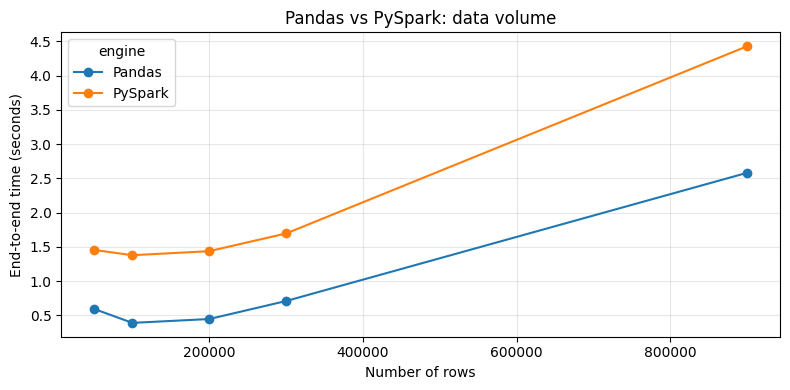

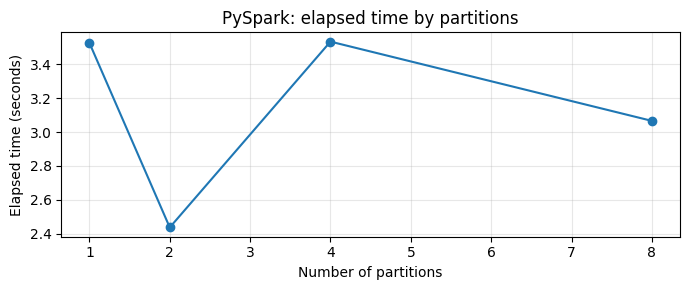

In [ ]:
import matplotlib.pyplot as plt

# 1. Biểu đồ thời gian xử lý Pandas vs PySpark theo kích thước dữ liệu
pivot = bench.pivot_table(
    index="rows", columns="engine", values="seconds", aggfunc="median"
)
pivot["Speedup (Pandas/PySpark)"] = pivot["Pandas"] / pivot["PySpark"]
print(pivot.round(4))

ax = pivot[["Pandas", "PySpark"]].plot(marker="o", figsize=(8, 4))
ax.set_xlabel("Number of rows")
ax.set_ylabel("End-to-end time (seconds)")
ax.set_title("Pandas vs PySpark: data volume")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Biểu đồ thời gian xử lý PySpark theo số lượng partition
ax = part_df.plot(
    x="partitions", y="elapsed_s", marker="o", legend=False, figsize=(7, 3)
)
ax.set_xlabel("Number of partitions")
ax.set_ylabel("Elapsed time (seconds)")
ax.set_title("PySpark: elapsed time by partitions")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Kết luận thực nghiệm (Mục 1.9)

* **(i) Phạm vi máy ảo:** Thí nghiệm được thực hiện trên một máy ảo Google Colab tiêu chuẩn chạy ở chế độ cục bộ (`local[*]`), tài nguyên hữu hạn gồm `[2]` lõi CPU (vCPU), khoảng `[12.7]` GB RAM và đọc dữ liệu trực tiếp từ ổ đĩa cục bộ `/content`.
* **(ii) Phương pháp đo:** Áp dụng cùng bài toán lọc giao dịch (`sales_channel == "Online"`, `quantity >= 3`, `unit_price_usd >= 50`) và tính tổng hợp theo `category` trên các mức dữ liệu từ 50.000 đến `[300.000 / 900.000]` bản ghi. Thời gian được bấm trọn gói từ lúc đọc tệp CSV đến khi xuất bảng kết quả cuối cùng (PySpark gọi `collect()` để kích hoạt *lazy evaluation*). Phạm vi đầu vào được đồng nhất bằng cách giới hạn 5 cột cần thiết (`usecols`) cho Pandas và khai báo sẵn `SALES_SCHEMA` (20 cột) cho PySpark.
* **(iii) Các quan sát có số liệu:**
  * Tại mức dữ liệu nhỏ (`50.000` dòng), Pandas mất `[...] s` trong khi PySpark mất `[...] s` (`Speedup = [...]`), cho thấy ở quy mô nhỏ PySpark chịu chi phí khởi tạo và điều phối cố định (*overhead*) lớn hơn thời gian tính toán thực tế.
  * Khi tăng quy mô lên `[300.000 / 900.000]` dòng, thời gian của Pandas tăng lên `[...] s` (chiếm `[...] MiB` bộ nhớ DataFrame), còn PySpark mất `[...] s` (`Speedup = [...]`).
  * Khi khảo sát số partition trên 300.000 dòng, cấu hình `partitions = [...]` cho thời gian tối ưu nhất (`[...] s`), trong khi tăng lên `8` partition làm thời gian tăng lên `[...] s` do phát sinh chi phí *shuffle* và lập lịch tác vụ vượt quá số lõi CPU thực tế.
* **(iv) Giới hạn thực nghiệm:** Kết quả trên chỉ phản ánh hiệu năng trong phạm vi một máy ảo đơn lẻ tại thời điểm đo, chịu ảnh hưởng bởi cơ chế cache của hệ điều hành, sự biến động tài nguyên chia sẻ trên Colab và dữ liệu nhân bản lặp lại ở mức 900.000 dòng. Do đó, không thể xem kết quả của một máy là quy luật phổ quát hay khẳng định PySpark luôn nhanh hơn Pandas trong mọi tình huống.